# Practical Task 1 — Industry Classification Using Business Description Embeddings and Financial Data

**Foundations of Data Science**

## Abstract
We classify 31,706 companies into 25 industries using pre-trained text embeddings of their business descriptions (768 dimensions). After exploring the data — including a large group of identical "placeholder" embeddings — we visualise the embedding space with PCA and compare two classical classifiers, **logistic regression** and **k-nearest neighbours (k-NN)**. Both reach about 77 % validation accuracy (baseline: 25 %); McNemar's test shows the difference is not significant. In the optional part we build an **ensemble** of both models, add **financial ratios** through empirical **p-values**, and analyse how well the model's confidence matches its accuracy. The final model reaches a confidence-weighted F1 score of **0.684** on the validation set and trains in under one minute.

## Structure
| Section | Content | Skeleton task |
|---|---|---|
| 1 | Setup | |
| 2 | Loading and understanding the data | Loading Data |
| 3 | Train / validation split | Loading Data |
| 4 | Label encoding | Transforming Data |
| 5 | Class distribution and PCA | Visualize the data |
| 6 | Logistic regression vs. k-NN | Fitting and comparing classifier models |
| 7 | Summary of the mandatory part | |
| 8 | Ensemble, confidence and financial data | Optional: confidence-weighted prediction |
| 9 | Final model and `predict` function | Optional: deliverable |
| 10 | Conclusion and limitations | |

Each step follows the same pattern: **Why** we do it → **code** → **Observations** (what the output tells us).

## 1. Setup
All libraries used in the notebook are imported once here.

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, binomtest, kruskal

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

## 2. Loading and understanding the data

Before building any model we want to answer a few basic questions:
1. What is one row, and which column is the **target** (what we predict) and which are the **features**?
2. Is anything missing?
3. What does the embedding look like — numbers or text? How many dimensions, on what scale?
4. Are there duplicates or other irregularities?

### 2.1 First look

In [2]:
df = pd.read_pickle("data/df_train.pkl")

print(df.shape)
df.head()

(31706, 3)


,id,industry,business_description_embedding
38532,42576,Banks,"[0.03411475,-0.03753958,0.023233214,-0.0017205..."
19838,21752,Materials,"[-0.025557408,0.0636078,-0.01350581,-0.0180223..."
904,804,Commercial & Professional Services,"[0.033574868,-0.020379327,-0.03221274,-0.01133..."
28806,31603,Insurance,"[0.020648101,0.017270269,-0.032921147,-0.01411..."
10472,11333,Capital Goods,"[-0.0006651232,0.011097765,-0.01976973,0.02299..."


**Observations**
- 31,706 rows and 3 columns. **One row = one company.**

| Column | Meaning | Role |
|---|---|---|
| `id` | company identifier | label only, not used for learning |
| `industry` | one of 25 industries (e.g. *Banks*, *Materials*) | **target** |
| `business_description_embedding` | the company description turned into numbers by a language model | **features** |

- The row index (38532, 19838, …) is not in order because the data was shuffled before it was given to us.
- **What is an embedding?** A language model reads the description text and outputs a list of numbers. Descriptions with similar meaning get similar lists, so two banks should have number lists that are close to each other. This is why we can hope to predict the industry from them.

### 2.2 Data types and missing values

In [3]:
print(df.dtypes)
print()
print(df.isna().sum())
print()
print("Number of industries:", df["industry"].nunique())
print()
first = df["business_description_embedding"].iloc[0]
print(type(first))
print(len(first))

id                                 int64
industry                          object
business_description_embedding    object
dtype: object

id                                0
industry                          0
business_description_embedding    0
dtype: int64

Number of industries: 25

<class 'str'>
9476


**Observations**
- **No missing values** in any column.
- **25 industries** → this is a **multi-class classification** problem. Random guessing would be right 1/25 = 4 % of the time.
- The embedding column has type `object`/`str`: it is stored as **text** like `"[0.034,-0.037,…]"` (9,476 characters), not as numbers. Python cannot compute with it, so we must convert it first. At roughly 12 characters per number we expect about 9,476 / 12.3 ≈ 770 values.

### 2.3 Converting the embeddings to numbers
**Why:** models need a numeric matrix. The text `[0.034, -0.037, …]` is valid JSON, so `json.loads` can turn it into a list of numbers. (The skeleton uses `ast.literal_eval`; both give the same result, `json.loads` is faster.)

In [4]:
X = np.array(df["business_description_embedding"].apply(json.loads).tolist())

print(X.shape)
print(X[0][:5])

(31706, 768)
[ 0.03411475 -0.03753958  0.02323321 -0.00172053 -0.00496361]


**Observations**
- `X` has 31,706 rows (one per company, in the same order as `df`) and **768 columns**. Each company is a point in a 768-dimensional space.
- The first five numbers match the text from Section 2.1, so the conversion is correct.

### 2.4 Scale and length of the vectors
**Why:** if some dimensions had much larger values than others, we would need to rescale (standardise) the data before using distance-based methods like k-NN.

In [5]:
print("smallest value:", X.min())
print("largest value: ", X.max())
print("mean:          ", X.mean())

lengths = np.linalg.norm(X, axis=1)   # length of each company's vector
print("vector length, min:", lengths.min())
print("vector length, max:", lengths.max())

smallest value: -0.22028096
largest value:  0.23074482
mean:           1.1503726109104004e-05
vector length, min: 0.9999998910388799
vector length, max: 1.0000001026570713


**Observations**
- All values are small (between −0.22 and +0.23) and centred around 0 → all dimensions are on the same scale, **no standardisation needed**.
- **Every vector has length 1** (up to rounding). The embedding model normalised them on purpose.

> **Methodology note — why length 1 matters.**
> The length of a vector is $\lVert x\rVert = \sqrt{x_1^2 + \dots + x_{768}^2}$. The usual measure of similarity between two descriptions is the **cosine similarity**
> $$\cos(x,z) = \frac{x\cdot z}{\lVert x\rVert\,\lVert z\rVert}.$$
> With $\lVert x\rVert = \lVert z\rVert = 1$ this is just the dot product $x\cdot z$, and the Euclidean distance becomes
> $$\lVert x-z\rVert^2 = \lVert x\rVert^2 + \lVert z\rVert^2 - 2\,x\cdot z = 2 - 2\cos(x,z).$$
> So **small distance = similar meaning**. This is exactly what k-NN (Section 6) relies on.

### 2.5 Duplicates
**Why:** duplicated companies or identical feature vectors can distort both training and evaluation.

In [6]:
print("duplicate ids:", df["id"].duplicated().sum())

emb = df["business_description_embedding"]
print("rows whose embedding appears more than once:", emb.duplicated(keep=False).sum())

print(emb.value_counts().head(5).values)

duplicate ids: 1
rows whose embedding appears more than once: 4631
[4359  116   19    9    9]


**Observations**
- Only **one** duplicated company id — negligible.
- But **4,631 rows share their embedding** with another row. Different companies can only have identical 768 numbers if their description text was identical.
- One single embedding is shared by **4,359 companies** (14 % of the data), another by 116. Small groups (2–19) can happen naturally (e.g. copy-pasted descriptions of sister companies); groups of thousands cannot. Our hypothesis: these companies had **no real description** (missing or a standard placeholder text), and that text was embedded.

### 2.6 Which industries share the most common embedding?

In [7]:
most_common = emb.value_counts().index[0]

same = df[emb == most_common]
print(len(same))
print(same["industry"].value_counts())

4359
industry
Materials                                       4348
Financial Services                                 2
Technology Hardware & Equipment                    2
Energy                                             2
Equity Real Estate Investment Trusts (REITs)       1
Capital Goods                                      1
Real Estate Management & Development               1
Consumer Durables & Apparel                        1
Transportation                                     1
Name: count, dtype: int64


**Observations**
- **4,348 of the 4,359 companies (99.7 %) are Materials.** This supports the placeholder hypothesis — probably a data source without descriptions for many mining/chemical companies.
- **Consequence for modelling:** a model can learn the trivial rule *"this exact vector → Materials"* and be right 99.7 % of the time without understanding any text. This inflates every score.
- **Decision:** we **keep** these rows (the private test set was most likely built the same way, so the rule is useful there too), but we **flag** them so we can report performance on real descriptions separately.

### 2.7 Flagging the "template" rows

In [8]:
counts = emb.value_counts()
template_embs = counts[counts >= 100].index   # the two big groups (4,359 and 116)

df["is_template"] = emb.isin(template_embs)

print(df["is_template"].sum())
print(df.loc[df["is_template"], "industry"].value_counts().head(3))

4475
industry
Materials                               4463
Financial Services                         2
Real Estate Management & Development       2
Name: count, dtype: int64


**Observations**
- **4,475 template rows** (4,359 + 116) = **14.1 %** of all companies; **4,463 of them are Materials**.
- There are 8,394 Materials companies in total, so **about 53 % of all Materials companies have no real description**. Materials will look like an "easy" industry partly for this reason.

## 3. Train / validation split

**Why:** a model always looks good on the data it was trained on. We hold back 10 % of the companies as a **validation set** that plays the role of new, unseen companies. Its score estimates how the model will perform on the private test set.

**Method:** we follow the skeleton (`test_size=0.1`, `random_state=42` for reproducibility). Since we already converted all embeddings into `X`, we select the matching rows of `X` for each part.

In [9]:
df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

X_train = X[df.index.get_indexer(df_train.index)]
X_val = X[df.index.get_indexer(df_val.index)]

print(df_train.shape, X_train.shape)
print(df_val.shape, X_val.shape)

(28535, 4) (28535, 768)
(3171, 4) (3171, 768)


**Observations**
- 28,535 training and 3,171 validation companies; features and labels line up (same number of rows).
- The split is **not stratified**, so class shares can differ slightly by chance. For the smallest industries (~20 validation companies) one company more or less changes their score by about 5 percentage points → **per-class scores for small industries are noisy**.

**Rule from here on:** the validation set is used **only for final evaluation**. All choices (hyperparameters, weights) are made on a separate tuning split of the training data (Section 6.3).

## 4. Transforming the data: label encoding

**Why:** models compute with numbers, not words. `LabelEncoder` maps each industry name to an integer 0–24 (alphabetical order). The numbers are only names — "Banks = 1" is not smaller than "Utilities = 24" — which is fine because both of our models treat the label as a category.

We also check that every validation industry also appears in training; otherwise it could never be predicted.

In [10]:
le = LabelEncoder()
le.fit(df_train["industry"])

y_train = le.transform(df_train["industry"])
y_val = le.transform(df_val["industry"])

print(le.classes_)
print(y_train[:10])
print(df_train["industry"].values[:3])

missing = set(df_val["industry"]) - set(df_train["industry"])
print("Industries in validation but not in training:", missing)

['Automobiles & Components' 'Banks' 'Capital Goods'
 'Commercial & Professional Services'
 'Consumer Discretionary Distribution & Retail'
 'Consumer Durables & Apparel' 'Consumer Services'
 'Consumer Staples Distribution & Retail' 'Energy'
 'Equity Real Estate Investment Trusts (REITs)' 'Financial Services'
 'Food, Beverage & Tobacco' 'Health Care Equipment & Services'
 'Household & Personal Products' 'Insurance' 'Materials'
 'Media & Entertainment' 'Pharmaceuticals, Biotechnology & Life Sciences'
 'Real Estate Management & Development'
 'Semiconductors & Semiconductor Equipment' 'Software & Services'
 'Technology Hardware & Equipment' 'Telecommunication Services'
 'Transportation' 'Utilities']
[10 21  5 15 12 15 24 17 19 17]
['Financial Services' 'Technology Hardware & Equipment'
 'Consumer Durables & Apparel']
Industries in validation but not in training: set()


**Observations**
- The 25 industries are numbered alphabetically (0 = Automobiles & Components, 1 = Banks, …, 15 = Materials, …, 24 = Utilities).
- Check: the first labels 10, 21, 5 correspond to *Financial Services*, *Technology Hardware & Equipment* and *Consumer Durables & Apparel* — exactly the names printed below them. ✓
- `set()` = empty set: **no industry is missing from the training data.** ✓

## 5. Visualising the data

### 5.1 Class distribution
**Why:** if some industries are much more common than others, a model can score well just by favouring them. This also tells us which metric to trust.

industry
Materials                                         8394
Capital Goods                                     3127
Financial Services                                1936
Pharmaceuticals, Biotechnology & Life Sciences    1925
Technology Hardware & Equipment                   1547
Software & Services                               1537
Energy                                            1326
Consumer Durables & Apparel                       1164
Food, Beverage & Tobacco                          1094
Health Care Equipment & Services                  1014
Banks                                              948
Media & Entertainment                              915
Real Estate Management & Development               906
Commercial & Professional Services                 804
Consumer Services                                  672
Consumer Discretionary Distribution & Retail       658
Automobiles & Components                           625
Semiconductors & Semiconductor Equipment           607
T

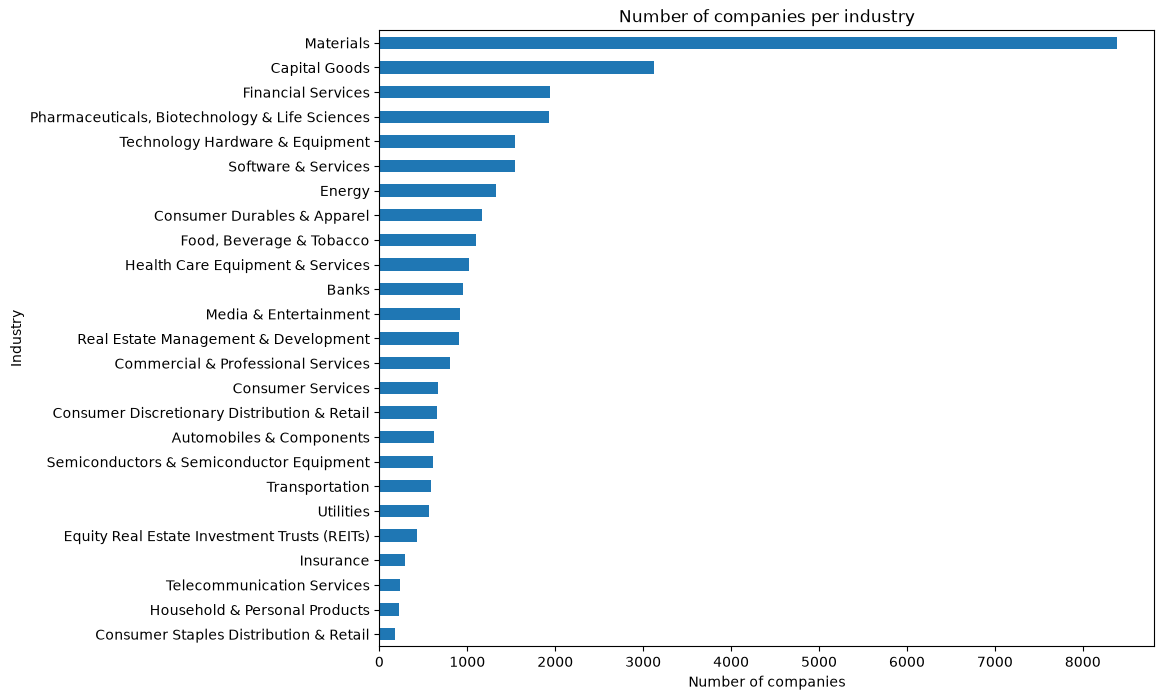

In [11]:
class_counts = df["industry"].value_counts()
print(class_counts)

plt.figure(figsize=(10, 8))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of companies")
plt.ylabel("Industry")
plt.title("Number of companies per industry")
plt.show()

**Observations**
- **Strongly imbalanced.** Materials has 8,394 companies (**26.5 %**); the smallest industry, Consumer Staples Distribution & Retail, has 178 (**0.6 %**) → **47× smaller**.
- With equal shares each industry would have 31,706 / 25 ≈ 1,268 companies; **18 of the 25 industries are below that**. The top 3 (Materials, Capital Goods, Financial Services) hold **42 %** of all companies.
- **Baseline:** always predicting "Materials" is right ~25 % of the time. A useful model must beat this clearly.
- **Consequence for metrics:** accuracy can look good if a model is only good at the big classes. We therefore also report **macro F1**, where every industry counts equally (Section 6.1).

### 5.2 PCA — reducing 768 dimensions to 2
**Why:** we cannot plot 768 dimensions. PCA finds the directions in which the data spreads out most; projecting onto the first two lets us see whether industries form separate groups — i.e. whether there is **signal** for classification.

> **Methodology — Principal Component Analysis**
> 1. **Centre** the data: subtract the mean vector from every company.
> 2. Compute the **covariance matrix** $\Sigma = \frac{1}{n-1}X_c^\top X_c$ (768 × 768); entry $\Sigma_{jk}$ says how dimensions $j$ and $k$ vary together.
> 3. Solve $\Sigma v = \lambda v$. The **eigenvectors** $v$ are the new axes (principal components); the **eigenvalues** $\lambda$ measure the variance along them. PC1 is the direction of largest variance, PC2 the next largest and orthogonal to PC1.
>    *Why eigenvectors?* We maximise the projected variance $v^\top\Sigma v$ subject to $\lVert v\rVert=1$; with a Lagrange multiplier this gives exactly $\Sigma v = \lambda v$.
> 4. **Project** each company onto $v_1, v_2$ to get its 2-D coordinates.
> 5. **Explained variance ratio** of a component $= \lambda_k / \sum_j \lambda_j$.
>
> PCA is fitted on the **training data only**.

In [12]:
pca = PCA(n_components=2)
pca.fit(X_train)

X_train_2d = pca.transform(X_train)

print(X_train_2d.shape)
print(pca.explained_variance_ratio_)
print("together:", pca.explained_variance_ratio_.sum())

(28535, 2)
[0.19296003 0.06101559]
together: 0.25397561864635615


**Observations**
- PC1 explains **19.3 %** and PC2 **6.1 %** of the variance — together only **25 %**. The 2-D plot is a strongly compressed view: separation in 2-D proves a difference, but overlap in 2-D does *not* prove overlap in 768-D.
- PC1 is more than 3× larger than PC2. A single dominant direction often points to an **outlier group** — possibly our template rows.

**Plot.** With 25 industries, 25 colours would be unreadable. We draw all companies in grey and highlight three industries that should be very different.

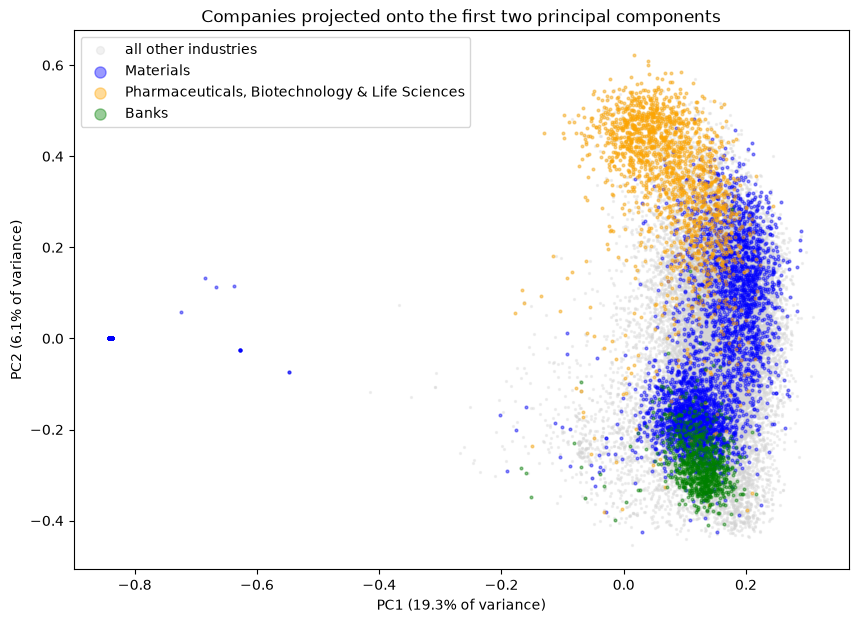

In [13]:
industries_train = df_train["industry"].values
highlight = [("Materials", "blue"),
             ("Pharmaceuticals, Biotechnology & Life Sciences", "orange"),
             ("Banks", "green")]

plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")
for name, color in highlight:
    mask = industries_train == name
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel("PC1 (19.3% of variance)")
plt.ylabel("PC2 (6.1% of variance)")
plt.title("Companies projected onto the first two principal components")
plt.legend(markerscale=4)
plt.show()

**Observations**
- **The dense point far left (PC1 ≈ −0.84) are the template rows** — thousands of identical vectors on one spot. PC1 mainly measures "template vs. real description", which squeezes all real companies into the narrow strip on the right.
- Even so, the three industries occupy **different regions**: Pharma at the top, Banks at the bottom, Materials in the middle (in two parts). There is overlap, but the grouping is clearly not random → **there is signal in the embeddings**.

### 5.3 PCA on real descriptions only
**Why:** to see the real structure, we refit PCA without the template rows. This is only for visualisation — the models still use all data.

[0.07509208 0.05616432]


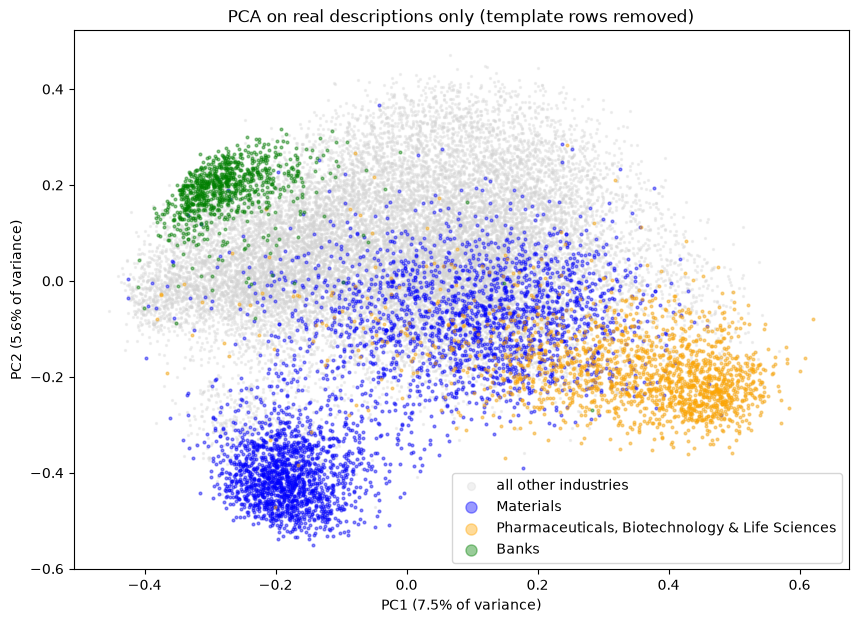

In [14]:
real = ~df_train["is_template"].values

pca_real = PCA(n_components=2)
X_real_2d = pca_real.fit_transform(X_train[real])
industries_real = industries_train[real]
ev = pca_real.explained_variance_ratio_ * 100
print(pca_real.explained_variance_ratio_)

plt.figure(figsize=(10, 7))
plt.scatter(X_real_2d[:, 0], X_real_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")
for name, color in highlight:
    mask = industries_real == name
    plt.scatter(X_real_2d[mask, 0], X_real_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel(f"PC1 ({ev[0]:.1f}% of variance)")
plt.ylabel(f"PC2 ({ev[1]:.1f}% of variance)")
plt.title("PCA on real descriptions only (template rows removed)")
plt.legend(markerscale=4)
plt.show()

**Observations**
- PC1 drops from 19.3 % to **7.5 %** (PC2: 5.6 %). This confirms that the dominant PC1 before was caused by the template rows.
- The three industries are now **clearly separated**: Banks form a tight cluster (top left), Pharma a cluster on the right, Materials the middle and bottom.
- **Materials consists of two groups**: a dense cluster at the bottom left (likely mining/mineral exploration companies with very similar descriptions) and a wider cloud (chemicals, steel, packaging, …). An industry can consist of several sub-groups — something a neighbour-based method like k-NN handles naturally.

### 5.4 One panel per industry
**Why:** the skeleton asks to colour the projection by class. Small multiples (one panel per industry, same axes) let us compare all 25 industries without unreadable colours.

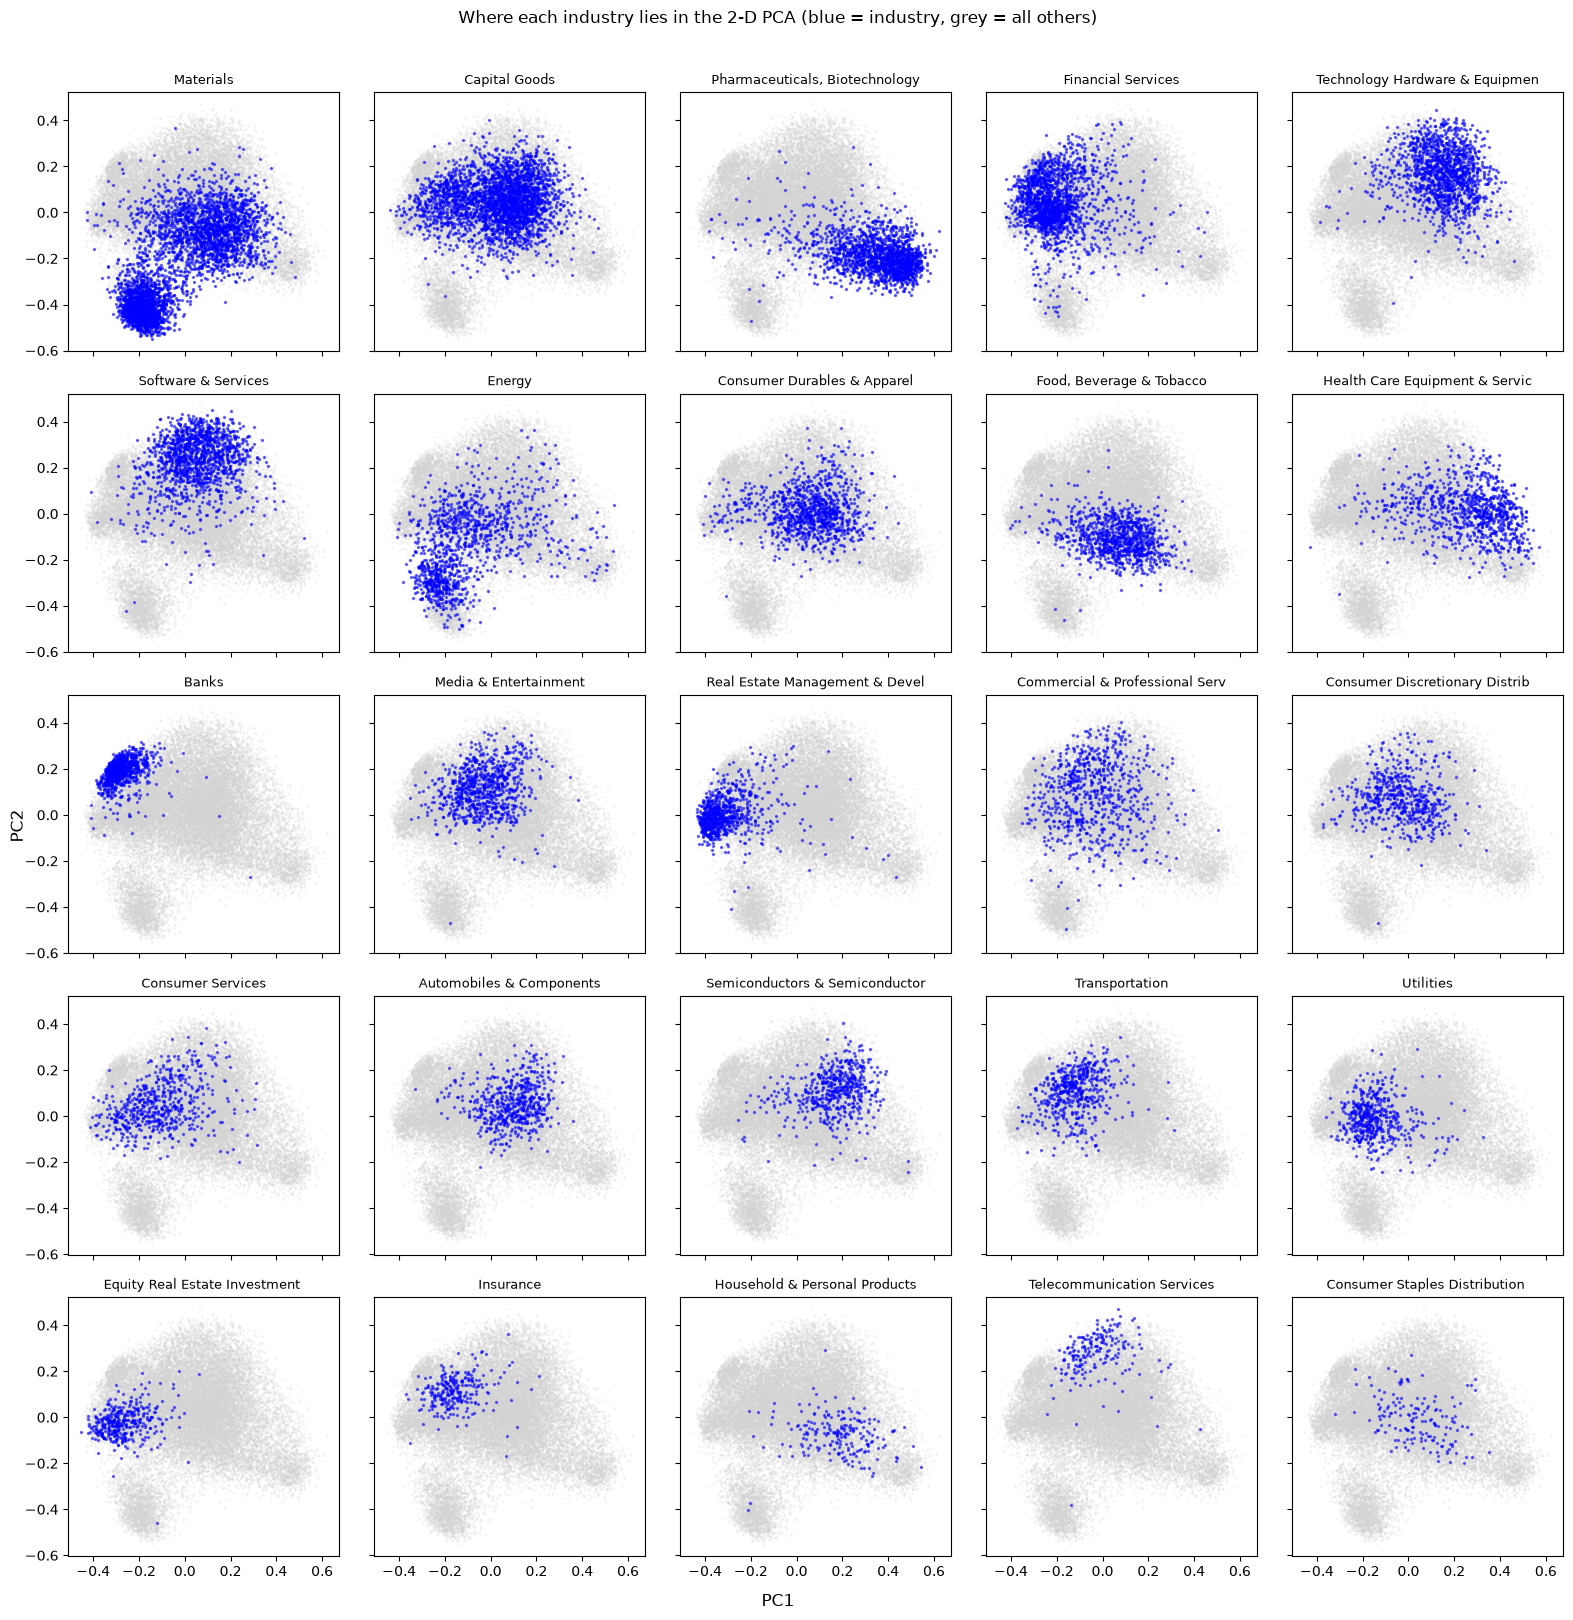

In [15]:
industry_names = df_train["industry"].value_counts().index

fig, axes = plt.subplots(5, 5, figsize=(16, 16), sharex=True, sharey=True)
for ax, name in zip(axes.flat, industry_names):
    mask = industries_real == name
    ax.scatter(X_real_2d[:, 0], X_real_2d[:, 1], s=1, c="lightgrey", alpha=0.2)
    ax.scatter(X_real_2d[mask, 0], X_real_2d[mask, 1], s=2, c="blue", alpha=0.5)
    ax.set_title(name[:30], fontsize=9)

fig.supxlabel("PC1")
fig.supylabel("PC2")
fig.suptitle("Where each industry lies in the 2-D PCA (blue = industry, grey = all others)", y=1.01)
plt.tight_layout()
plt.show()

**Observations**

| Pattern | Industries | Expectation |
|---|---|---|
| Compact, separate clusters | Banks, Real Estate, REITs, Pharma/Biotech, Materials (mining cluster); clear centres for Software, Tech Hardware, Food & Beverage | easy to classify |
| Spread over the centre | Capital Goods (broad "industrial" category), Commercial & Professional Services, Consumer Services, Consumer Discretionary Retail, Consumer Durables, Media | hard |
| Small and overlapping | Consumer Staples Retail (sits where Food & Beverage is), Household & Personal Products | hard |
| Two parts | Energy (one part on top of the Materials mining cluster), Materials | partly confused with each other |

- **Related industries are neighbours**: the finance group (Banks, Financial Services, Insurance, Real Estate, REITs) on the left, the tech group (Software, Tech Hardware, Semiconductors, Telecom) top right, the health group (Pharma, Health Care Equipment, Household Products) on the right. The embedding space reflects real economic relationships.

**Conclusion of Section 5:** there is **clear signal** in the embeddings for industry classification. We expect distinct industries to be easy and the "central" and very small industries to be hard — a prediction we test in Section 6.

## 6. Fitting and comparing classifier models

### 6.1 Methodology

> **Logistic regression (multinomial / softmax).** For each industry $c$ the model learns 768 weights $w_c$ and a bias $b_c$, computes a score $z_c = w_c\cdot x + b_c$ and turns the 25 scores into probabilities with the **softmax**
> $$P(y=c\mid x) = \frac{e^{z_c}}{\sum_{j=1}^{25} e^{z_j}}.$$
> The weights minimise the **cross-entropy loss** plus an L2 penalty:
> $$\mathcal{L} = -\sum_i \log P(y_i\mid x_i) + \frac{1}{2C}\lVert W\rVert^2 .$$
> The loss is small when the true industry gets a high probability ($-\log 0.9 = 0.1$) and large when it gets a low one ($-\log 0.01 = 4.6$). **C** controls the penalty: small C = strong penalty = simpler model. Decision boundaries are flat hyperplanes → a **linear** model.

> **k-nearest neighbours.** No formula is learned; the training companies are stored. To classify $x$: compute the distance to all training companies, take the $k$ closest and let them **vote**. Because our vectors have length 1, nearest = most similar description (Section 2.4). k-NN can follow any shape of class boundary, but large classes are more likely to appear among the neighbours.

> **Metrics.** For one industry: **precision** = of all companies predicted as this industry, the share that is correct; **recall** = of all companies truly in this industry, the share that was found; **F1** = $2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$. Averaged over industries: **weighted F1** weights each industry by its size (dominated by big classes); **macro F1** weights all industries equally. A large gap between the two means small industries are handled worse.

### 6.2 First models with default settings

In [16]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_val)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_val)

majority = np.bincount(y_train).argmax()          # most frequent class = Materials
pred_base = np.full(len(y_val), majority)

def get_scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 weighted": f1_score(y_true, y_pred, average="weighted"),
        "F1 macro": f1_score(y_true, y_pred, average="macro"),
    }

results_default = pd.DataFrame({
    "Baseline (always Materials)": get_scores(y_val, pred_base),
    "Logistic regression (default, C = 1)": get_scores(y_val, pred_lr),
    "k-NN (default, k = 5)": get_scores(y_val, pred_knn),
}).T
results_default.round(3)

,Accuracy,F1 weighted,F1 macro
Baseline (always Materials),0.249,0.099,0.016
"Logistic regression (default, C = 1)",0.772,0.766,0.695
"k-NN (default, k = 5)",0.753,0.750,0.680


**Observations**
- Both models are about **3× better than the baseline** (77 % / 75 % vs 25 % accuracy) → the embeddings carry strong industry information.
- Logistic regression is ~2 points ahead of k-NN on all metrics.
- Macro F1 is ~7 points below weighted F1 for both models → small industries are classified worse on average.
- This comparison is not yet fair: both use **default hyperparameters**.

### 6.3 Hyperparameter tuning
**Why:** C (logistic regression) and k (k-NN) are chosen *before* training. We must not choose them by looking at the validation score — that would make the validation score optimistic. Instead, we split the training data again: 85 % to fit, 15 % to compare settings (**tuning set**).

In [17]:
X_fit, X_tune, y_fit, y_tune = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

for k in [1, 5, 10, 15, 25, 50]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_fit, y_fit)
    pred = model.predict(X_tune)
    print("k =", k, " F1 weighted =", round(f1_score(y_tune, pred, average="weighted"), 4))

k = 1  F1 weighted = 0.7126
k = 5  F1 weighted = 0.751
k = 10  F1 weighted = 0.7632
k = 15  F1 weighted = 0.7631
k = 25  F1 weighted = 0.7549
k = 50  F1 weighted = 0.7489


**Observations (k-NN)**
- **k = 1 is worst** (0.713): copying a single neighbour is too sensitive to noise (**overfitting**).
- **k = 10–15 is best** (0.763): several neighbours vote, so one odd neighbour is outvoted.
- **Large k** slowly gets worse: the vote reaches dissimilar companies and big industries start to win (**underfitting**).
- This U-shape is the **bias–variance trade-off**. We choose **k = 10**.

In [18]:
for C in [0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_fit, y_fit)
    pred = model.predict(X_tune)
    print("C =", C, " F1 weighted =", round(f1_score(y_tune, pred, average="weighted"), 4))

C = 0.1  F1 weighted = 0.7151
C = 1  F1 weighted = 0.7652
C = 10  F1 weighted = 0.7696


**Observations (logistic regression)**
- **C = 0.1** (strong penalty) is clearly worse → the model is too simple to separate 25 industries (underfitting).
- **C = 10** is best, only slightly above C = 1 → we are near the optimum.
- With ~28,000 companies for ~19,000 weights (25 × 769) there is enough data that a weak penalty does not lead to overfitting. We choose **C = 10**.

### 6.4 Final comparison on the validation set
Both models are retrained with the chosen settings on the **full** training set and evaluated once on the validation set.

In [19]:
lr = LogisticRegression(C=10, max_iter=1000)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_val)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_val)

results = pd.DataFrame({
    "Baseline (always Materials)": get_scores(y_val, pred_base),
    "Logistic regression (C = 10)": get_scores(y_val, pred_lr),
    "k-NN (k = 10)": get_scores(y_val, pred_knn),
}).T
results.round(3)

,Accuracy,F1 weighted,F1 macro
Baseline (always Materials),0.249,0.099,0.016
Logistic regression (C = 10),0.777,0.774,0.713
k-NN (k = 10),0.772,0.767,0.695


How much of this comes from the "free" template rows? We compute the accuracy separately for template rows and real descriptions:

In [20]:
template_val = df_val["is_template"].values
for name, pred in [("Logistic regression", pred_lr), ("k-NN", pred_knn)]:
    print(f"{name}: template rows {accuracy_score(y_val[template_val], pred[template_val]):.3f}"
          f" | real descriptions {accuracy_score(y_val[~template_val], pred[~template_val]):.3f}")

Logistic regression: template rows 1.000 | real descriptions 0.743
k-NN: template rows 1.000 | real descriptions 0.736


**Observations**
- **Tuning helped both models**: logistic regression +0.5 points accuracy and +1.8 points macro F1; k-NN +1.9 points accuracy (k = 5 was too noisy).
- Logistic regression is slightly ahead on every metric (0.777 vs 0.772 accuracy). The gap is about 16 companies — whether it is real is tested in Section 6.8.
- **Template rows are always correct** (100 %); on **real descriptions accuracy is about 74 %**. This is the honest measure of what the models learned from text.
- For 25 partly overlapping industries this is a good result.

### 6.5 Performance per industry
**Why:** averages hide differences between industries.

In [21]:
print(classification_report(y_val, pred_lr, target_names=le.classes_, digits=2))

                                                precision    recall  f1-score   support

                      Automobiles & Components       0.76      0.70      0.73        53
                                         Banks       0.99      0.95      0.97        74
                                 Capital Goods       0.66      0.74      0.70       322
            Commercial & Professional Services       0.61      0.42      0.50        78
  Consumer Discretionary Distribution & Retail       0.70      0.63      0.66        67
                   Consumer Durables & Apparel       0.70      0.61      0.66       127
                             Consumer Services       0.70      0.72      0.71        81
        Consumer Staples Distribution & Retail       0.29      0.20      0.24        20
                                        Energy       0.81      0.59      0.68       152
  Equity Real Estate Investment Trusts (REITs)       0.76      0.82      0.79        45
                            Fin

**Observations (logistic regression)**

| Easiest industries | F1 | Hardest industries | F1 |
|---|---|---|---|
| Banks | 0.97 | Consumer Staples Distribution & Retail | 0.24 |
| Materials | 0.93 | Commercial & Professional Services | 0.50 |
| Food, Beverage & Tobacco | 0.84 | Household & Personal Products | 0.53 |
| Pharma/Biotech | 0.82 | Technology Hardware & Equipment | 0.62 |
| Transportation | 0.82 | Consumer Durables, Consumer Discretionary Retail, Software | 0.66 |

- The easy industries are exactly the **compact clusters** from Section 5.4. **Banks** is small (3 % of data) but has the best score → being small does not automatically mean being hard.
- The hard industries are either **small and overlapping** (Consumer Staples Retail, Household Products) or **spread out / overlapping** (Commercial Services, Tech Hardware, Software).
- **Precision vs. recall:**
  - *Energy* (precision 0.81, recall 0.59): rarely wrongly predicted, but misses 41 % of energy companies — oil & gas explorers look like mining explorers.
  - *Capital Goods* (precision 0.66 < recall 0.74): predicted **too often** — a broad category that attracts other industrial-sounding companies.
- Industries with only ~20 validation companies have uncertain scores (one company ≈ 5 points).

### 6.6 Do the errors correlate with class size?
**Why:** the skeleton asks whether errors depend on how well classes are represented.

> **Methodology — Spearman rank correlation.** Rank the 25 industries by size and by F1, then correlate the ranks ($\rho = 1$: bigger always better; $\rho = 0$: no relation). Ranks are robust to the very skewed class sizes.
> **Hypothesis test:** $H_0$: no relation ($\rho = 0$). The p-value is the probability of a correlation at least this strong if $H_0$ were true. If p < 0.05 we reject $H_0$.

Spearman correlation: 0.17  p-value: 0.406


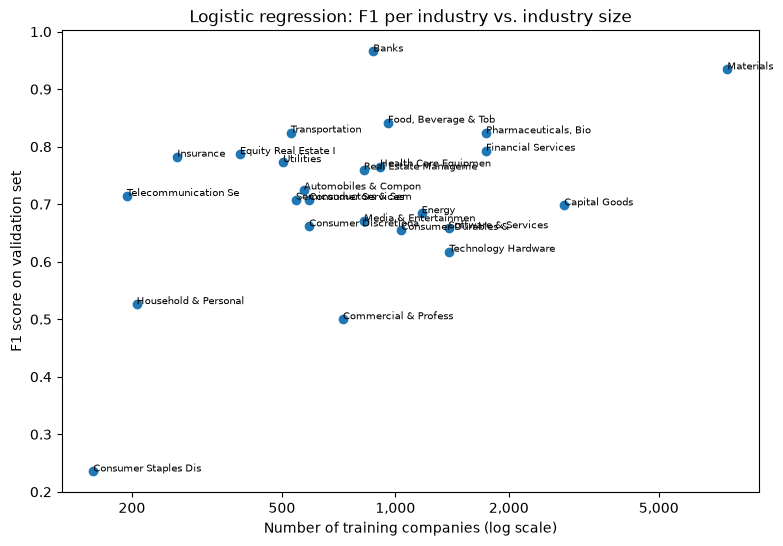

In [22]:
f1_per_class = f1_score(y_val, pred_lr, average=None)
train_size = np.bincount(y_train)

rho, p = spearmanr(train_size, f1_per_class)
print("Spearman correlation:", round(rho, 2), " p-value:", round(p, 3))

plt.figure(figsize=(9, 6))
plt.scatter(train_size, f1_per_class)
for i, name in enumerate(le.classes_):
    plt.annotate(name[:20], (train_size[i], f1_per_class[i]), fontsize=7)
plt.xscale("log")
plt.xticks([200, 500, 1000, 2000, 5000], ["200", "500", "1,000", "2,000", "5,000"])
plt.minorticks_off()
plt.xlabel("Number of training companies (log scale)")
plt.ylabel("F1 score on validation set")
plt.title("Logistic regression: F1 per industry vs. industry size")
plt.show()

**Observations**
- $\rho = 0.17$, **p = 0.41** → we **cannot reject $H_0$**: there is no significant relation between industry size and F1.
- Counter-examples: Banks (small, best F1), Insurance/REITs/Telecom (small, F1 0.71–0.79), Capital Goods (2nd largest, F1 only 0.70).
- Only the **very smallest and overlapping** industries (Consumer Staples Retail, Household Products) clearly suffer.
- **Answer:** performance depends more on **how distinctive an industry's descriptions are** than on its size.

### 6.7 Confusion matrices
**Why:** to see *which* industries are mixed up. Entry (i, j) = share of companies of true industry i predicted as j. Rows are normalised to percentages so that small industries remain visible; the diagonal equals the recall.

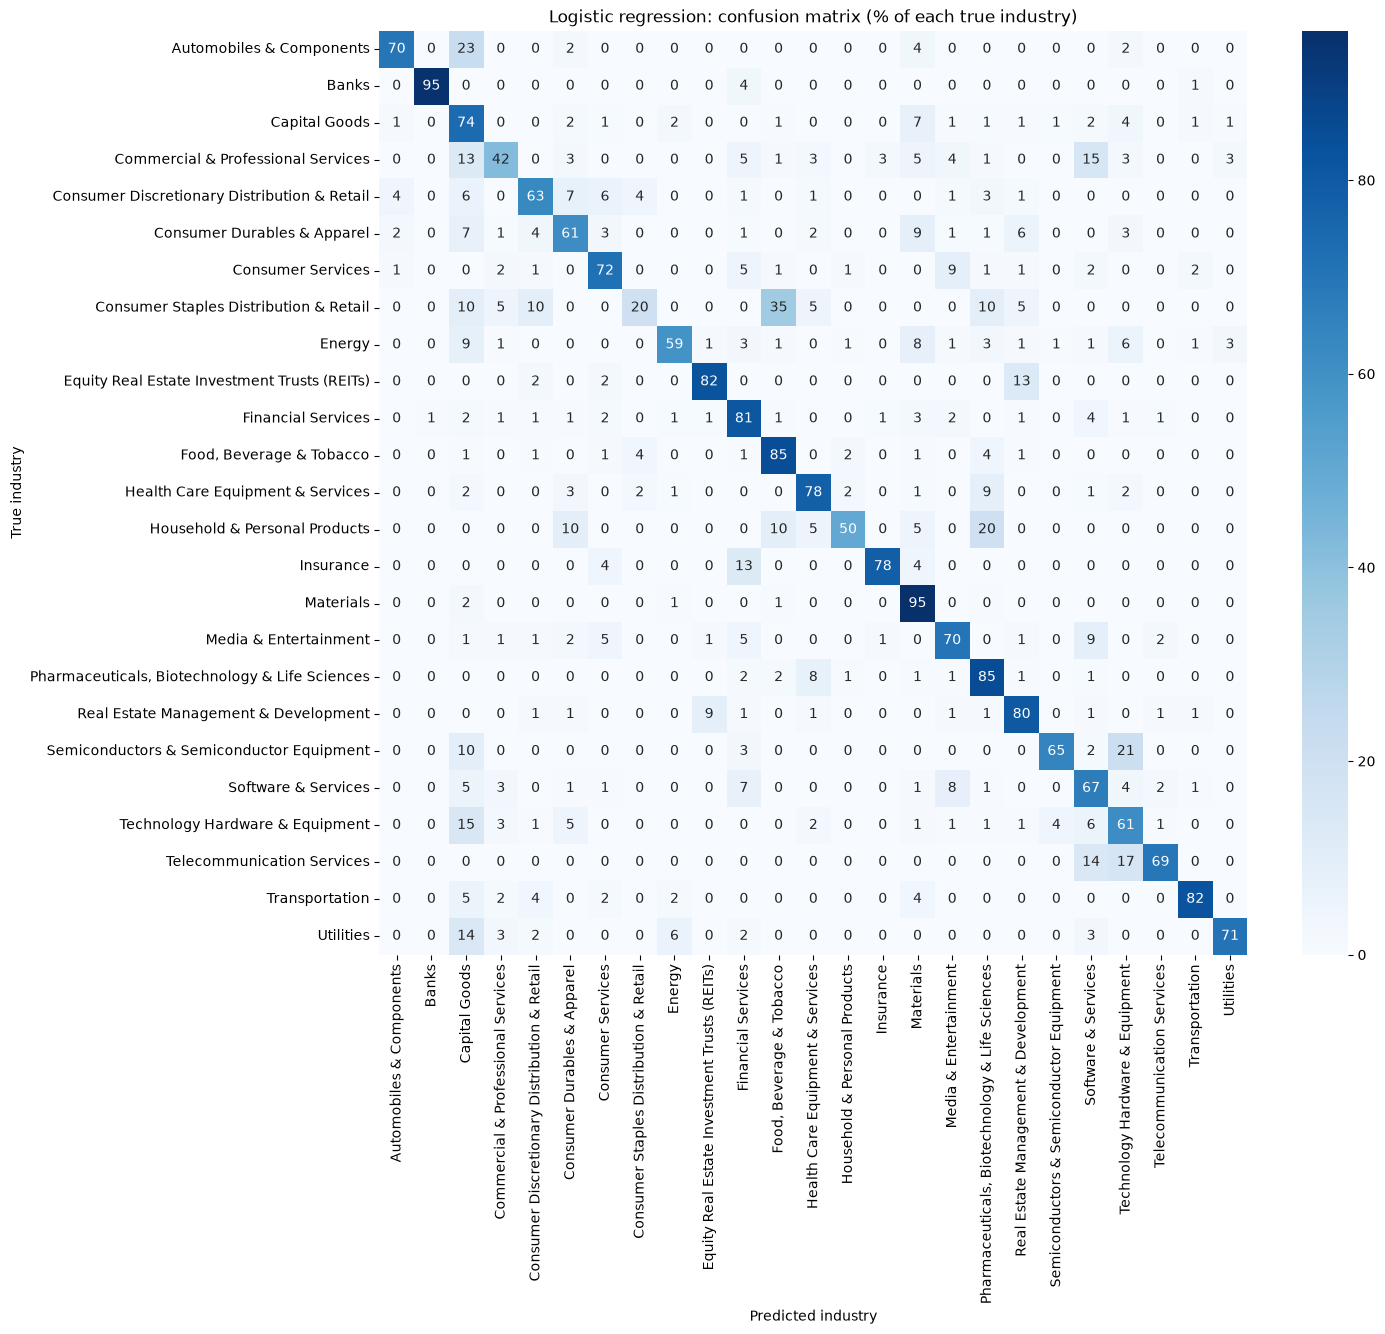

In [23]:
cm = confusion_matrix(y_val, pred_lr, normalize="true") * 100

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted industry")
plt.ylabel("True industry")
plt.title("Logistic regression: confusion matrix (% of each true industry)")
plt.show()

**Observations (logistic regression) — most frequent confusions**

| True industry | → Predicted as | % | Explanation |
|---|---|---|---|
| Consumer Staples Retail | Food, Beverage & Tobacco | 35 | supermarket descriptions are full of food words |
| Automobiles & Components | Capital Goods | 23 | car-parts makers sound like machinery makers |
| Semiconductors | Technology Hardware | 21 | closely related sectors |
| Household & Personal Products | Pharma/Biotech | 20 | cosmetics sound like health products |
| Telecom | Tech Hardware / Software | 17 / 14 | networks, devices, digital services |
| Commercial & Prof. Services | Software & Services | 15 | IT services, consulting |
| Technology Hardware | Capital Goods | 15 | electronic vs. industrial equipment |
| Utilities | Capital Goods | 14 | power generation equipment |
| REITs | Real Estate Management | 13 | both own and manage property |
| Insurance | Financial Services | 13 | both are finance |

- Almost all confusions are between **economically similar industries** — the same neighbours as in the PCA plots.
- **Capital Goods acts as a "sink"**: it receives errors from many industries (Automobiles, Tech Hardware, Utilities, Commercial Services, …). This explains its low precision.

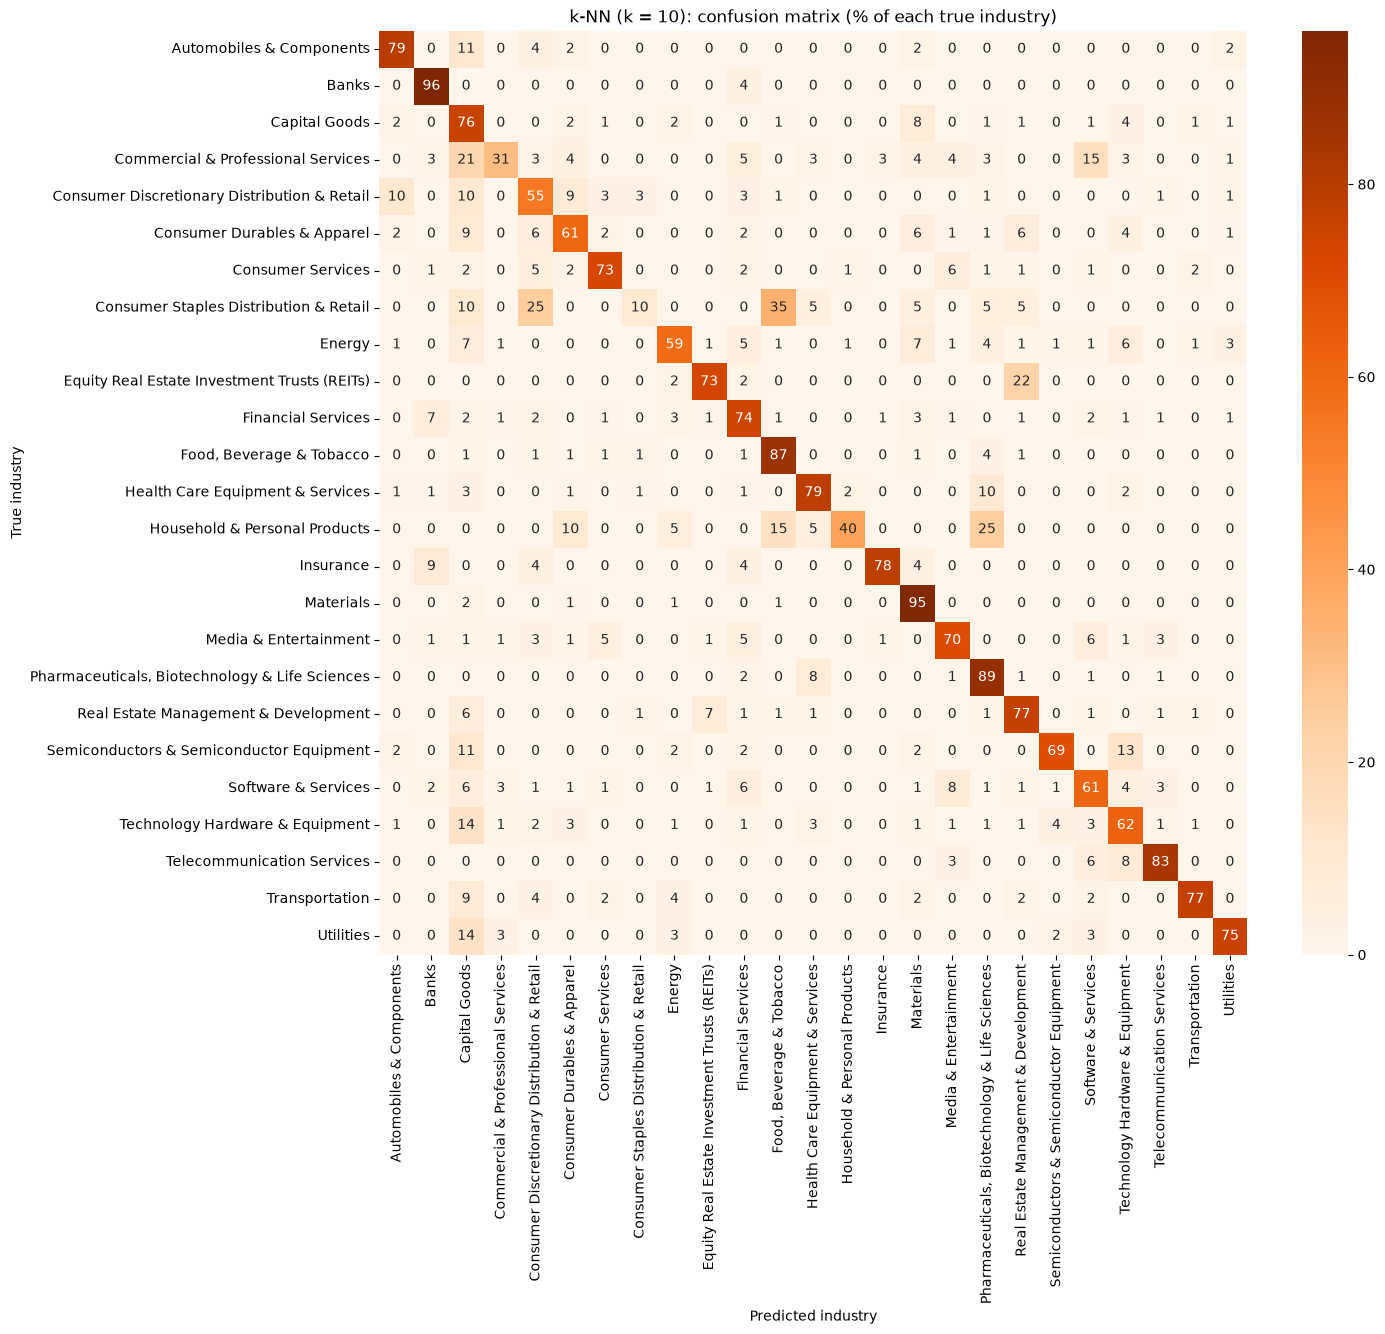

In [24]:
cm_knn = confusion_matrix(y_val, pred_knn, normalize="true") * 100

plt.figure(figsize=(14, 12))
sns.heatmap(cm_knn, annot=True, fmt=".0f", cmap="Oranges",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted industry")
plt.ylabel("True industry")
plt.title("k-NN (k = 10): confusion matrix (% of each true industry)")
plt.show()

**Observations (k-NN vs. logistic regression)**
- k-NN makes **mostly the same confusions** — both models use the same embeddings.
- Where the two models differ most (recall in %):

| Industry | LR | k-NN | Better | Why |
|---|---|---|---|---|
| Consumer Staples Retail | 20 | 10 | LR | food producers outvote supermarkets among the neighbours |
| Household & Personal Products | 50 | 40 | LR | small class, neighbours often Pharma |
| Commercial & Prof. Services | 42 | 31 | LR | spread out, no clear neighbourhood |
| REITs | 82 | 73 | LR | neighbours often Real Estate Management |
| Telecommunication Services | 69 | 83 | k-NN | compact sub-groups |
| Automobiles & Components | 70 | 79 | k-NN | fewer pulled into Capital Goods |
| Pharma/Biotech | 85 | 89 | k-NN | very dense cluster |

- **k-NN struggles with small classes**: big neighbouring industries win the vote. Logistic regression learns a separate weight vector per class and handles them better.
- **k-NN over-predicts Banks** (7 % of Financial Services and 9 % of Insurance are called "Banks"), because the dense bank cluster dominates the neighbourhood of nearby finance companies.

### 6.8 Do both models misclassify the same companies?

In [25]:
lr_right = pred_lr == y_val
knn_right = pred_knn == y_val

print("both right:        ", np.sum(lr_right & knn_right))
print("only LR right:     ", np.sum(lr_right & ~knn_right))
print("only k-NN right:   ", np.sum(~lr_right & knn_right))
print("both wrong:        ", np.sum(~lr_right & ~knn_right))

both_wrong = ~lr_right & ~knn_right
same_wrong = np.sum(pred_lr[both_wrong] == pred_knn[both_wrong])
print("both wrong AND same wrong answer:", same_wrong)

both right:         2256
only LR right:      209
only k-NN right:    191
both wrong:         515
both wrong AND same wrong answer: 415


**Observations**

|  | k-NN right | k-NN wrong |
|---|---|---|
| **LR right** | 2,256 | 209 |
| **LR wrong** | 191 | 515 |

- **Mostly yes:** 73 % of LR's errors (515 of 706) are also made by k-NN, and in **81 %** of these shared errors both predict the **same wrong industry**. These companies genuinely look like another industry in embedding space (ambiguous descriptions, border cases such as REITs ↔ Real Estate, possibly a few wrong labels).
- **But not entirely:** 400 companies are classified correctly by exactly one model. At least one model is right for **83.8 %** of companies (vs 77.7 % for LR alone) → combining the models could help.
- **Agreement is a confidence signal:** when both models agree they are right **84.5 %** of the time; when they disagree each is right only ~40 %.

**Is LR significantly better?**
> **Methodology — McNemar's test.** Both models are evaluated on the same companies, so we use a paired test. Only the disagreements carry information: b = LR right & k-NN wrong, c = the opposite. Under $H_0$ (equal error rates) each disagreement is a fair coin flip, so $b \sim \text{Binomial}(b+c, 0.5)$. The exact p-value is the probability of a split at least as uneven as observed.

In [26]:
b = np.sum(lr_right & ~knn_right)
c = np.sum(~lr_right & knn_right)

result = binomtest(b, b + c, 0.5)
print("b =", b, " c =", c)
print("p-value:", round(result.pvalue, 3))

b = 209  c = 191
p-value: 0.395


**Observations**
- **p = 0.395** ≫ 0.05 → a split of 209 vs 191 is very plausible under $H_0$. **The difference between the models is not statistically significant**; overall they perform equally well.
- We would still prefer **logistic regression** in practice: better on the smallest industries and Banks precision (higher macro F1), faster at prediction, and it outputs meaningful probabilities. k-NN is better for industries made of tight sub-groups (Telecom, Automobiles) — the models **complement** each other.

## 7. Summary of the mandatory part

| Model (validation set) | Accuracy | F1 weighted | F1 macro |
|---|---|---|---|
| Baseline (always Materials) | 0.249 | 0.099 | 0.016 |
| Logistic regression (C = 10) | 0.777 | 0.774 | 0.713 |
| k-NN (k = 10) | 0.772 | 0.767 | 0.695 |

- **Data:** 31,706 companies, 25 industries, 768-dimensional unit-length embeddings, no missing values; 14 % placeholder ("template") embeddings, almost all Materials.
- **Class distribution:** strongly imbalanced (Materials 26.5 %, smallest industry 0.6 %).
- **PCA:** 2 components keep ~25 % of the variance; on real descriptions many industries form distinct clusters → clear signal.
- **Models:** both ~3× better than the baseline; hyperparameters chosen on a tuning split. On real descriptions accuracy is ~74 %.
- **Errors vs. class size:** no significant correlation (Spearman ρ = 0.17, p = 0.41); distinctiveness of the descriptions matters more.
- **Confusions:** between economically similar industries; Capital Goods attracts many errors.
- **Same errors?** Mostly (73 % shared); difference not significant (McNemar p = 0.40); at least one model is right for 83.8 % → basis for an ensemble.

## 8. Optional part: confidence-weighted prediction

### 8.1 The scoring function
The model must output a prediction and a confidence in [0, 1] for every company. Submissions are scored with
$$\text{score} = F_1^{\text{weighted}} \cdot (1 - \text{Brier}), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n}\big(\text{conf}_i - \mathbb{1}[\text{prediction}_i \text{ correct}]\big)^2 .$$

| Confidence | Prediction | Penalty |
|---|---|---|
| 0.9 | right | $(0.9-1)^2 = 0.01$ |
| 0.9 | wrong | $(0.9-0)^2 = 0.81$ |
| 1.0 | wrong | $1.0$ (maximum) |

The best strategy is a **calibrated** confidence: among predictions with confidence 0.8, about 80 % should be correct.

In [27]:
def confidence_score(y_true, y_pred, confidence):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)